In [5]:
# Libraries
import sys

import site
import numpy as np
import requests as req
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import csv
import pandas as pd
import scipy as sc

In [6]:
import netCDF4
from scipy.special import kl_div
from scipy.stats import entropy

In [7]:
# parameters of interest:
date_start = "2013-09-01"
date_end = "2013-10-01"
buoy_id = "bid17"

# Model

## Data Request

Using the following to obtain data:

https://erddap.riddc.brown.edu/erddap/tabledap/osom_v2_0585_f867_db94.html

In [8]:
def get_model_data(station, start_date, end_date, start_time="00:00:00", end_time="00:00:00"):
    datasetID = "osom_v2_0585_f867_db94"
    file_type = ".nc"
    variables = "SalinityBottom%2CSalinitySurface%2CWaterTempBottom%2CWaterTempSurface%2CSurfaceHeight%2CVelocityEastwardBottom%2CVelocityEastwardSurface%2CVelocityNorthwardBottom%2CVelocityNorthwardSurface%2CKineticEnergyBottom%2CKineticEnergySurface%2Ctime%2Cstation_name%2Clatitude%2Clongitude"

    time_start_query = "time%3E=" + start_date + "T" + start_time.replace(":", "%3A") + "Z"
    time_end_query = "time%3C=" + end_date + "T" + end_time.replace(":", "%3A") + "Z"
    station_name_query = "station_name=" + "%22" + station + "%22"

    queries = "&" + "&".join([time_start_query, time_end_query, station_name_query])
    form_request = "https://erddap.riddc.brown.edu/erddap/tabledap/" + datasetID + file_type + "?" + variables + queries

    response = req.get(form_request)
    response.raise_for_status()
    return xr.open_dataset(response.content)

In [9]:
# Obtain buoy data

def get_buoy_data(station, start_date, end_date, start_time="00:00:00", end_time="00:00:00"):
    datasetID = "combined_e784_bee5_492e"
    file_type = ".nc"
    variables = "time%2Cstation_name%2CO2PercentSurface%2CO2PercentBottom%2Cdepth%2CSalinityBottom%2CpHBottom%2CDepthBottom%2CTurbidityBottom%2CChlorophyllSurface%2CpHSurface%2CSpCondSurface%2CSpCondBottom%2CFSpercentSurface%2CWaterTempBottom%2CO2Surface%2CO2Bottom%2CWaterTempSurface%2CSalinitySurface%2CDensitySurface%2CDensityBottom%2Clatitude%2Clongitude"

    time_start_query = "time%3E=" + start_date + "T" + start_time.replace(":", "%3A") + "Z"
    time_end_query = "time%3C=" + end_date + "T" + end_time.replace(":", "%3A") + "Z"
    station_name_query = "station_name=" + "%22" + station + "%22"

    queries = "&" + "&".join([time_start_query, time_end_query, station_name_query])

    form_request = "https://erddap.riddc.brown.edu/erddap/tabledap/" + datasetID + file_type + "?" + variables + queries

    response = req.get(form_request)
    response.raise_for_status()

    return xr.open_dataset(response.content)

In [10]:
buoy_data = get_buoy_data(buoy_id, date_start, date_end)
model_data = get_model_data(buoy_id, date_start, date_end)

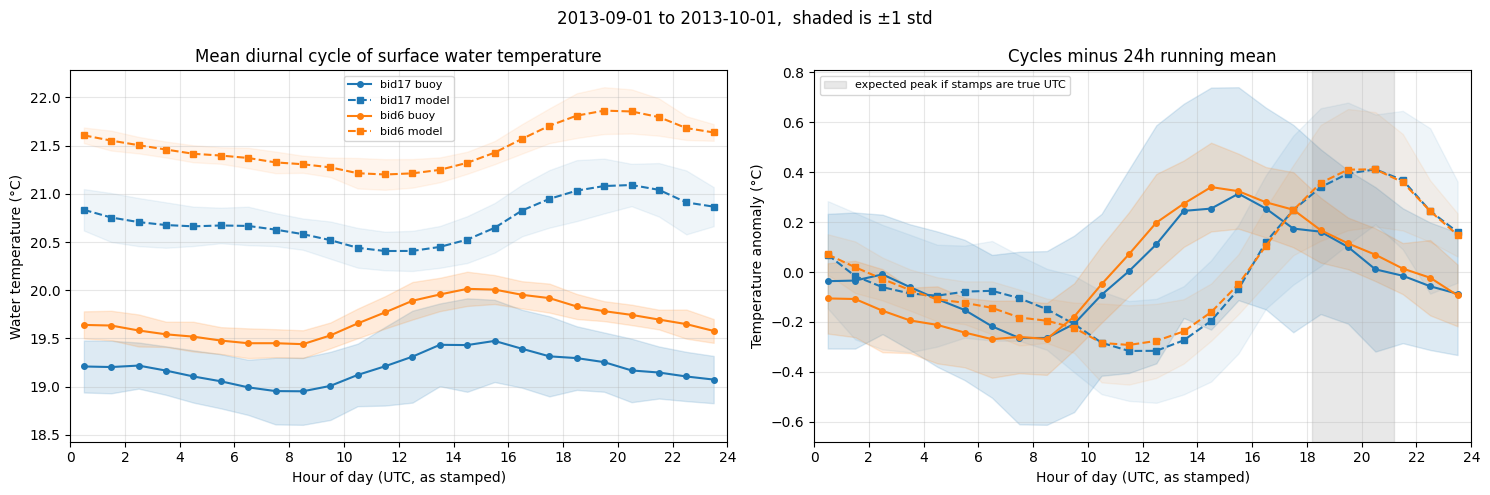

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HOURS = np.arange(24) + 0.5
OMEGA = 2 * np.pi / 24
HEATING_LAG_H = 3.0
LAG_UNCERTAINTY_H = 1.5

def _wrap(x):
    return (np.asarray(x) + 12) % 24 - 12

def _regular_grid(s, step="15min", max_gap="3h"):
    s = s.dropna()
    grid = pd.date_range(s.index.min().ceil(step), s.index.max().floor(step), freq=step)
    out = s.reindex(s.index.union(grid)).interpolate("time", limit_area="inside").reindex(grid)
    idx = s.index.to_series()
    span = idx.reindex(grid, method="bfill") - idx.reindex(grid, method="ffill")
    out[(span > pd.Timedelta(max_gap)).to_numpy()] = np.nan
    return out

def _day_hour_matrices(s):
    grid = _regular_grid(s)
    anom = grid - grid.rolling(96, center=True, min_periods=72).mean()
    def to_mat(x):
        m = x.groupby([x.index.normalize(), x.index.hour]).mean().unstack().reindex(columns=range(24))
        return m[m.notna().sum(axis=1) >= 20]
    return to_mat(grid), to_mat(anom)

def _fit_peak(mat):
    m = np.nanmean(np.asarray(mat), axis=0)
    ok = ~np.isnan(m)
    X = np.column_stack([np.ones(24), np.cos(OMEGA * HOURS), np.sin(OMEGA * HOURS)])[ok]
    c = np.linalg.lstsq(X, m[ok], rcond=None)[0]
    return (np.arctan2(c[2], c[1]) / OMEGA) % 24, 2 * np.hypot(c[1], c[2])

def _circ_std(h):
    a = np.asarray(h) * OMEGA
    R = np.hypot(np.mean(np.cos(a)), np.mean(np.sin(a)))
    return np.sqrt(-2 * np.log(R)) / OMEGA

def _bootstrap(mat_a, mat_b, n=2000, seed=0):
    days = mat_a.index.intersection(mat_b.index)
    A, B = mat_a.loc[days].to_numpy(), mat_b.loc[days].to_numpy()
    rng = np.random.default_rng(seed)
    pa, pb = np.empty(n), np.empty(n)
    for i in range(n):
        k = rng.integers(0, len(days), len(days))
        pa[i], pb[i] = _fit_peak(A[k])[0], _fit_peak(B[k])[0]
    peak_a, amp_a = _fit_peak(A)
    peak_b, amp_b = _fit_peak(B)
    diff = float(_wrap(peak_a - peak_b))
    return dict(peak_a=peak_a, peak_b=peak_b, amp_a=amp_a, amp_b=amp_b,
                std_a=_circ_std(pa), std_b=_circ_std(pb),
                diff=diff, std_diff=float(np.std(_wrap(pa - pb - diff))), n_days=len(days))

def _solar_noon_utc(lon, date):
    B = np.deg2rad(360 / 365 * (date.dayofyear - 81))
    eot_min = 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B)
    return 12 - lon / 15 - eot_min / 60

def single_diurnal_cycle(station, start_date, variable="WaterTempSurface"):
    start = pd.Timestamp(start_date)
    end = start + pd.DateOffset(months=1) - pd.Timedelta(days=1)
    args = (station, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d"), "00:00:00", "23:59:59")
    out = {"mid_date": start + (end - start) / 2}
    for kind, fetch in [("buoy", get_buoy_data), ("model", get_model_data)]:
        ds = fetch(*args)
        s = pd.Series(np.asarray(ds[variable].values, dtype=float), index=pd.to_datetime(ds["time"].values))
        s = s[~s.index.duplicated()].sort_index().dropna()
        abs_mat, anom_mat = _day_hour_matrices(s)
        out[kind] = {"abs": abs_mat, "anom": anom_mat, "lon": float(np.nanmean(ds["longitude"].values))}
    return out

def compute_diurnal_cycles(station_1, station_2, start_date, variable="WaterTempSurface"):
    return {st: single_diurnal_cycle(st, start_date, variable) for st in (station_1, station_2)}

station_1 = "bid17"
station_2 = "bid6"

cycles = compute_diurnal_cycles(station_1, station_2, date_start)

colors = {station_1: "tab:blue", station_2: "tab:orange"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

for st, res in cycles.items():
    for kind, ls, mk in [("buoy", "-", "o"), ("model", "--", "s")]:
        for ax, key in [(ax1, "abs"), (ax2, "anom")]:
            mat = res[kind][key]
            mean, std = mat.mean(), res[kind]["anom"].std()
            ax.plot(HOURS, mean.values, ls=ls, marker=mk, ms=4, lw=1.5, color=colors[st],
                    label=f"{st} {kind}" if ax is ax1 else None)
            ax.fill_between(HOURS, (mean - std).values, (mean + std).values, color=colors[st],
                            alpha=0.07 if kind == "model" else 0.15)

ref = cycles[station_1]
expected_utc = _solar_noon_utc(ref["buoy"]["lon"], ref["mid_date"]) + HEATING_LAG_H
ax2.axvspan(expected_utc - LAG_UNCERTAINTY_H, expected_utc + LAG_UNCERTAINTY_H, color="gray", alpha=0.18,
            label="expected peak if stamps are true UTC")

ax1.set_title("Mean diurnal cycle of surface water temperature")
ax1.set_ylabel("Water temperature (°C)")
ax2.set_title("Cycles minus 24h running mean")
ax2.set_ylabel("Temperature anomaly (°C)")
for ax in (ax1, ax2):
    ax.set_xlabel("Hour of day (UTC, as stamped)")
    ax.set_xticks(range(0, 25, 2))
    ax.set_xlim(0, 24)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle(f"" + date_start + " to " + date_end + ",  shaded is ±1 std")
plt.tight_layout()
plt.show()

In [12]:
rows, diff_rows = [], []
for st, res in cycles.items():
    r = _bootstrap(res["buoy"]["anom"], res["model"]["anom"])
    for kind, peak, amp, std in [("buoy", r["peak_a"], r["amp_a"], r["std_a"]),
                                 ("model", r["peak_b"], r["amp_b"], r["std_b"])]:
        expected = _solar_noon_utc(res[kind]["lon"], res["mid_date"]) + HEATING_LAG_H
        offset = float(_wrap(peak - expected))
        rows.append({
            "series": f"{st} {kind}",
            "days": r["n_days"],
            "p-p amp (°C)": round(amp, 2),
            "peak hour (stamped)": round(peak, 2),
            "peak ± (h, 1σ boot)": round(std, 2),
            "implied offset (h)": round(offset, 2),
            "± total (h)": round(float(np.hypot(std, LAG_UNCERTAINTY_H)), 2),
            "nearest zone": f"UTC{round(offset):+d}",
        })
    diff_rows.append({
        "station": st,
        "buoy peak − model peak (h)": round(r["diff"], 2),
        "± (h, 1σ paired boot)": round(r["std_diff"], 2),
    })

print(pd.DataFrame(rows).to_string(index=False))
print()
print(pd.DataFrame(diff_rows).to_string(index=False))

     series  days  p-p amp (°C)  peak hour (stamped)  peak ± (h, 1σ boot)  implied offset (h)  ± total (h) nearest zone
 bid17 buoy    28          0.39                17.07                 0.41               -2.60         1.56        UTC-3
bid17 model    28          0.57                21.28                 0.25                1.61         1.52        UTC+2
  bid6 buoy    24          0.54                16.55                 0.14               -3.12         1.51        UTC-3
 bid6 model    24          0.58                20.99                 0.12                1.32         1.51        UTC+1

station  buoy peak − model peak (h)  ± (h, 1σ paired boot)
  bid17                       -4.22                   0.39
   bid6                       -4.44                   0.13
